1. Import

In [1]:
from pathlib import Path
import re
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

sns.set_theme()
pd.set_option("display.max_colwidth", 100)

2. Loaded the cleaned dataset

In [2]:
PROJECT_ROOT = Path.cwd().parent

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
MODELS_DIR = PROJECT_ROOT / "models"

MODELS_DIR.mkdir(parents=True, exist_ok=True)

DATA_PATH = PROCESSED_DIR / "products_cleaned.csv"

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found: {DATA_PATH}"
        f"Run NoteBook 1 first"
    )

df = pd.read_csv(DATA_PATH)

print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())
display(df.head())

Dataset shape: (196, 7)
Columns: ['product_id', 'name', 'category', 'brand', 'price', 'stock', 'rating']


,product_id,name,category,brand,price,stock,rating
0,1,MacBook Pro M4 14,Laptop,Apple,10677.59,10.0,4.7
1,2,RTX 5070 Ti 16GB,GPU,NVIDIA,771.27,13.0,4.9
2,3,Core Ultra 5 245K,CPU,Intel,323.46,12.0,4.3
3,4,16GB DDR5-5600,RAM,Kingston,50.02,47.0,4.2
4,5,27in 4K OLED 240Hz,Monitor,ASUS,891.30,5.0,4.7


3. Select text and target

In [3]:
REQUIRED_COLUMNS = ["name", "category"]

missing_columns = [
    col for col in REQUIRED_COLUMNS
    if col not in df.columns
]

if missing_columns:
    raise ValueError(
        f"Missing required columns: {missing_columns}"
    )

df = df[REQUIRED_COLUMNS].copy()

df["name"] = df["name"].fillna("").astype(str).str.strip()
df["category"] = df["category"].fillna("").astype(str).str.strip()

df = df[
    (df["name"] != "") &
    (df["category"] != "")
].copy()

df = df.reset_index(drop=True)

print("Dataset Shape after filtering:", df.shape )
print("Unique categories:", df["category"].unique())
display(df.head())

Dataset Shape after filtering: (196, 2)
Unique categories: ['Laptop' 'GPU' 'CPU' 'RAM' 'Monitor' 'SSD' 'Motherboard' 'Mouse' 'Case'
 'Headset' 'PSU']


,name,category
0,MacBook Pro M4 14,Laptop
1,RTX 5070 Ti 16GB,GPU
2,Core Ultra 5 245K,CPU
3,16GB DDR5-5600,RAM
4,27in 4K OLED 240Hz,Monitor


4. Clean product Name

In [4]:
def clean_product_name(text):

    text = str(text).lower()

    text = re.sub(r"https?://\S+|www.\.\S+"," ",text)

    text = re.sub(r"<[^>]+>"," ", text)

    text = re.sub(r"[^\w\s\-\+\.]", " ", text)

    text = re.sub(r"\s+", " ", text).strip()

    return text

df["clean_name"] = df["name"].apply(clean_product_name)

display(df[["name", "clean_name", "category"]].head(10))

,name,clean_name,category
0,MacBook Pro M4 14,macbook pro m4 14,Laptop
1,RTX 5070 Ti 16GB,rtx 5070 ti 16gb,GPU
2,Core Ultra 5 245K,core ultra 5 245k,CPU
3,16GB DDR5-5600,16gb ddr5-5600,RAM
4,27in 4K OLED 240Hz,27in 4k oled 240hz,Monitor
5,Ryzen 7 9700X,ryzen 7 9700x,CPU
6,2TB 990 PRO,2tb 990 pro,SSD
7,Core Ultra 5 245K,core ultra 5 245k,CPU
8,1TB 990 EVO Plus,1tb 990 evo plus,SSD
9,B650 Tomahawk WiFi,b650 tomahawk wifi,Motherboard


5. Analyze text data

In [5]:
df["text_length"] = df["clean_name"].str.len()
df["word_count"] = (df["clean_name"]).str.split().str.len()

print("Average text length:", df["text_length"].mean())
print("Average word count:", df["word_count"].mean())

display(df.groupby("category") [["text_length", "word_count"]].mean().round(2))

Average text length: 14.479591836734693
Average word count: 3.020408163265306


,text_length,word_count
category,,
CPU,14.66,3.34
Case,7.75,1.88
GPU,14.11,3.52
Headset,21.43,3.57
Laptop,16.29,3.29
Monitor,15.50,3.50
Motherboard,18.42,3.25
Mouse,18.60,4.07
PSU,15.64,2.73


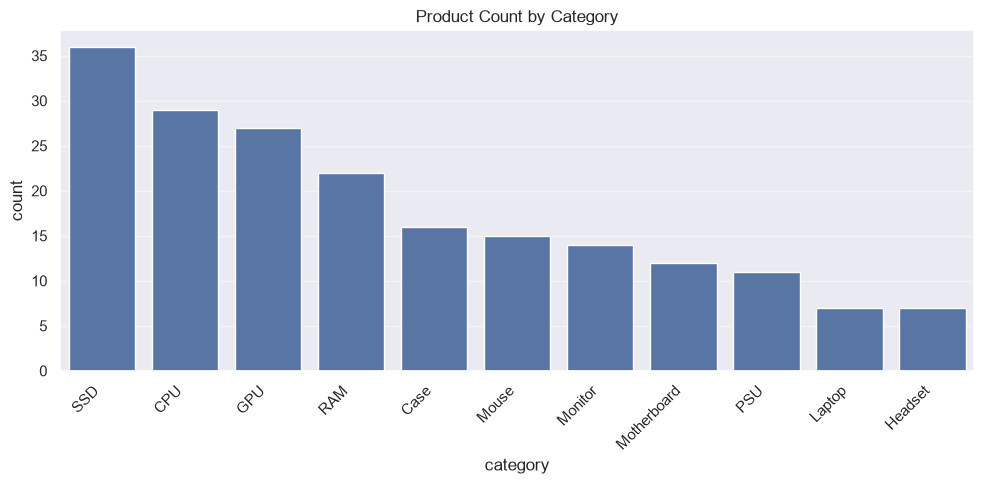

In [6]:
plt.figure(figsize=(10, 5))
sns.countplot(data=df, x="category", order=df["category"].value_counts().index)

plt.title("Product Count by Category")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

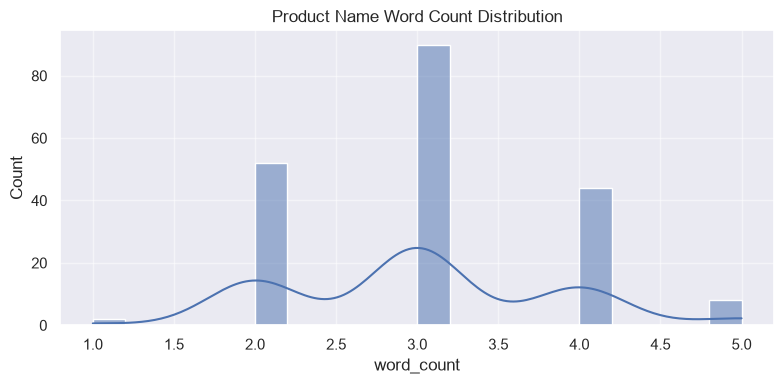

In [7]:
plt.figure(figsize=(8,4))
sns.histplot(data=df, x="word_count", bins=20, kde=True)
plt.title("Product Name Word Count Distribution")
plt.tight_layout()
plt.show()

6. Train / Test Split

In [8]:
x_test = df["clean_name"]
y = df["category"]

category_counts = y.value_counts()
stratify_target = (
    y
    if y.nunique() > 1 and category_counts.min() >= 2
    else None
)
try:
    x_train, x_test, y_train, y_test = train_test_split(x_test, y, test_size=0.20, stratify=stratify_target)

except ValueError:
    x_train, x_test, y_train, y_test = train_test_split(x_test, y, test_size=0.20, random_state=42)

print("Training examples:", len(x_train))
print("Test examples:", len(x_test))

print("\nTraining Categories:", y_train.value_counts())

Training examples: 156
Test examples: 40

Training Categories: category
SSD            29
CPU            23
GPU            21
RAM            17
Case           13
Mouse          12
Monitor        11
PSU             9
Motherboard     9
Headset         6
Laptop          6
Name: count, dtype: int64


7. TF-IDF + Logistic Regression & Train the model

In [9]:
nlp_model = Pipeline([
    ("tfidf", TfidfVectorizer(
        lowercase=True,
        ngram_range=(1, 2),
        max_features=10000,
        min_df=1,
        sublinear_tf=True
    )),
    ("classifier",
     LogisticRegression(
         max_iter=3000,
         class_weight="balanced",
         random_state=42)
     )
])

print(nlp_model)

nlp_model.fit(x_train, y_train)
print("NLP model training Completed")

Pipeline(steps=[('tfidf',
                 TfidfVectorizer(max_features=10000, ngram_range=(1, 2),
                                 sublinear_tf=True)),
                ('classifier',
                 LogisticRegression(class_weight='balanced', max_iter=3000,
                                    random_state=42))])
NLP model training Completed


8. Accuracy, precision, recall, F1-score

In [10]:
y_pred = nlp_model.predict(x_test)

test_accuracy = accuracy_score(y_test, y_pred)
print("NLP Test Accuracy:", round(test_accuracy, 4))
print(classification_report(y_test, y_pred, zero_division=0))

NLP Test Accuracy: 1.0
              precision    recall  f1-score   support

         CPU       1.00      1.00      1.00         6
        Case       1.00      1.00      1.00         3
         GPU       1.00      1.00      1.00         6
     Headset       1.00      1.00      1.00         1
      Laptop       1.00      1.00      1.00         1
     Monitor       1.00      1.00      1.00         3
 Motherboard       1.00      1.00      1.00         3
       Mouse       1.00      1.00      1.00         3
         PSU       1.00      1.00      1.00         2
         RAM       1.00      1.00      1.00         5
         SSD       1.00      1.00      1.00         7

    accuracy                           1.00        40
   macro avg       1.00      1.00      1.00        40
weighted avg       1.00      1.00      1.00        40



9. Confusion matrix

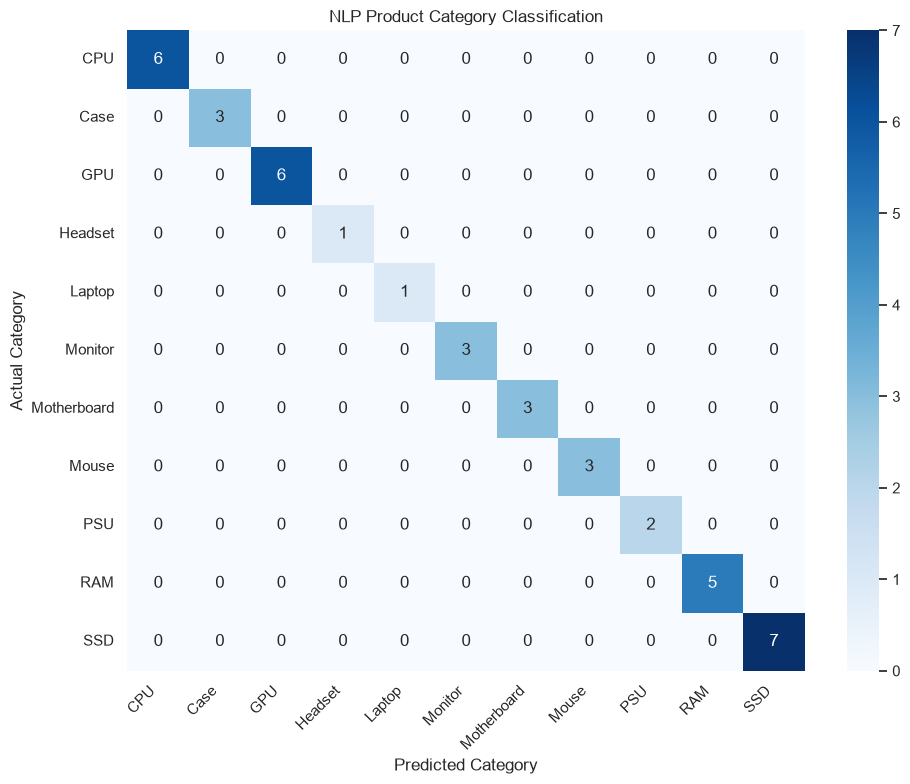

In [11]:
all_labels = sorted(y.unique())

cm = confusion_matrix(y_test, y_pred, labels=all_labels)

plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=all_labels, yticklabels=all_labels)

plt.title("NLP Product Category Classification")
plt.xlabel("Predicted Category")
plt.ylabel("Actual Category")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

10. Save Trained model

In [12]:
MODEL_PATH = (MODELS_DIR / "product_name_tfidf_classifier.joblib")
METADATA_PATH = (MODELS_DIR / "product_name_tfidf_metadata.json")

joblib.dump(nlp_model, MODEL_PATH)

metadata = {
    "model_name": "TF-IDF + Logistic Regression",
    "text_column" : "name",
    "target_column" : "category",
    "test_accuracy" : float(test_accuracy),
    "random_state" : 42
}

with open(METADATA_PATH, "w", encoding="utf-8") as file:
    json.dump(metadata, file, indent=2)

print("Model saved:", MODEL_PATH)
print("Metadata saved:", METADATA_PATH)


Model saved: /Users/macbookpro/PycharmProjects/Techcart_ai/models/product_name_tfidf_classifier.joblib
Metadata saved: /Users/macbookpro/PycharmProjects/Techcart_ai/models/product_name_tfidf_metadata.json


11. Load & Predict

In [14]:
loaded_nlp_model = joblib.load(MODEL_PATH)

new_product_name = "Samsung 990 Pro 1TB NVMe M.2 SSD"

cleaned_text = clean_product_name(new_product_name)
predicted_category = loaded_nlp_model.predict([cleaned_text])[0]

print("Product:", new_product_name)
print("Predicted Category:", predicted_category)

probabilities = loaded_nlp_model.predict_proba([cleaned_text])[0]
classes = loaded_nlp_model.classes_

top_indices = np.argsort(probabilities)[::-1][:5]

for index in top_indices:
    print(
        f"{classes[index]}: {probabilities[index]:.4f}"

    )

Product: Samsung 990 Pro 1TB NVMe M.2 SSD
Predicted Category: SSD
SSD: 0.4617
Mouse: 0.0844
CPU: 0.0588
GPU: 0.0545
Motherboard: 0.0536
